# Segmentación de clientes — Desembolsos Capital de Trabajo (IBK BdN)

Este notebook construye la segmentación de clientes de Capital de Trabajo
usada en el proyecto **IBK BdN (VOI)**: 9 segmentos finales (6 para clientes
con historial de deuda en el sistema financiero y 3 para clientes sin ese
historial), obtenidos a partir de dos **árboles de decisión** entrenados
sobre el descuento de tasa otorgado (`diff_tea`).

**Contenido:**
1. Carga y preparación de la base de desembolsos
2. Cruce con las ofertas del funnel (tasa y monto ofertados)
3. Cruce con variables de comportamiento del cliente
4. Feature engineering (SOW de deuda, descuento de tasa, dummies)
5. **Modelo final 1** — árbol para clientes CON historial de deuda (6 clusters)
6. **Modelo final 2** — árbol para clientes SIN historial de deuda (3 clusters)
7. Asignación final de clusters (reglas de negocio extraídas de los árboles)
8. Evolución de la composición de los clusters en el tiempo (N y monto)
9. Validación de estabilidad del segmento en el tiempo (PSI)
10. Perfil de los clusters
11. Tabla resumen por cluster y exportación
12. Aplicación de la segmentación a la data actualizada


## 0. Imports y configuración

In [32]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import uniform, randint

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.4f}'.format)

RANDOM_STATE = 42  

## 1. Carga y preparación de la base de desembolsos

Población de interés: desembolsos de **Banca de Negocios** (`flg_poblacion_objetivo == 1`)
del producto **Capital de Trabajo**, entre 202503 y 202605. Se seleccionan
solo las columnas necesarias para el análisis.

In [33]:
ruta_desembolsos = r"C:/Users/Lenovo/Streaming de Google Drive/.shortcut-targets-by-id/14G2D9-Gte-83zSj-crVkwplKt-CX4FE6/11_IBK BdN Cliente360/01_ Solicitud Datos/Tablon_Unificado/01_DesembOrig_2022/V11_Tabla originación 2022(20260828).csv"

cols_desembolsos = [
    'key_value', 'cod_credito', 'cod_unico', 'tipo_cliente', 'cartera_final',
    'banca_final', 'tamano_empresa', 'tipo_colocacion', 'periodo', 'plazo',
    'monto_desembolsado', 'campana_vpc', 'tasa',
    'canal_final', 'producto', 'flg_retanqueo',
]

df = pd.read_csv(ruta_desembolsos)
df = df[df['flg_poblacion_objetivo']==1]
df = df[cols_desembolsos].copy()
df = df[(df.producto == 'CAPITAL DE TRABAJO') & (df.periodo.between(202503, 202605))].copy()

print(f"Base de desembolsos: {df.shape[0]:,} filas, {df.shape[1]} columnas")


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_32476\981768265.py:10: DtypeWarning: Columns (1,11,12,13,25,33,34,35,36,125,214,218,222,226) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta_desembolsos)


Base de desembolsos: 10,902 filas, 16 columnas


Se construyen tres campos auxiliares. La **TEA** se pasa de porcentaje a decimal para que sea comparable con la tasa ofertada del funnel. La **llave interna** (`key_value` + periodo) identifica al cliente en un mes y es la que permite cruzar con el funnel y con la tabla de variables. Finalmente, `tamano_empresa` se imputa con la moda porque es una variable categórica descriptiva con pocos faltantes (1.5%), no entra al modelo, así que esta imputación no afecta los clusters.

In [34]:
# copia del canal final
df['canal_final_copy'] = df['canal_final'].copy()

# imputación de tamano_empresa con la moda 
df['tamano_empresa'] = df['tamano_empresa'].fillna(df['tamano_empresa'].mode().values[0])

# tea
df['tea'] = df['tasa'] / 100

# llave_interna
df['llave_interna'] = df['key_value'] + "-" + df['periodo'].astype(str)

print(f"Rango de periodos: {df.periodo.min()} a {df.periodo.max()}")


Rango de periodos: 202503 a 202605


## 2. Cruce con el funnel de leads (oferta vs. desembolso)

Para cada desembolso se busca la oferta que lo originó, con la misma llave cliente-mes y el mismo canal. Del funnel se conservan solo las campañas comerciales relevantes (excluyendo programas de gobierno) y las ofertas que tienen monto ofertado. Como un cliente puede tener más de una oferta en el mes y canal, se agregan el mínimo y el máximo de tasa, monto y plazo ofertados.

In [35]:
ruta_leads = r"C:/Users/Lenovo/Streaming de Google Drive/.shortcut-targets-by-id/14G2D9-Gte-83zSj-crVkwplKt-CX4FE6/11_IBK BdN Cliente360/01_ Solicitud Datos/Tablon_Unificado/04_Funnel/funnel_leads_V01.csv"

df_leads = pd.read_csv(ruta_leads)
df_leads = df_leads[(df_leads.producto == 'CAPITAL DE TRABAJO') & df_leads.periodo.between(202503, 202605)]
df_leads['llave_interna'] = df_leads['key_value'] + "-" + df_leads['periodo'].astype(str)
df_leads = df_leads[df_leads.llave_interna.isin(df['llave_interna'].values)]
df_leads = df_leads.drop(columns=['key_value_ruc_pn', 'cod_unico'])
df_leads['campanha'] = df_leads['campanha'].str.upper()

# Campañas comerciales
campanhas_validas = [
    'NUEVO APROBADO AGIL',
    'NUEVO APROBADO EN',
    'NUEVO PRE-APROBADO',
    'RECURRENTE ÁGIL CEM',
]
df_leads = df_leads[df_leads.campanha.isin(campanhas_validas)]

# Filtro por no tener oferta
df_leads = df_leads[~df_leads.monto_ofertado_cmp.isna()]

print(f"Ofertas (leads) tras filtros: {df_leads.shape[0]:,} filas")


Ofertas (leads) tras filtros: 10,871 filas


In [36]:
# Se agrega el min/max de oferta en tasa, monto y plazo ofertados 
df_cruce = df_leads.groupby(['llave_interna', 'canal_inicial_ofertalead']).agg(
    conteo=('key_value', 'count'),
    tasa_min=('tasa_piso_ofertado_cmp', 'min'),
    tasa_max=('tasa_piso_ofertado_cmp', 'max'),
    monto_min=('monto_ofertado_cmp', 'min'),
    monto_max=('monto_ofertado_cmp', 'max'),
    plazo_min=('plazo_ofertado_cmp', 'min'),
    plazo_max=('plazo_ofertado_cmp', 'max'),
).reset_index()

print(f"Antes del cruce: {df.shape}")
df = pd.merge(
    df, df_cruce,
    left_on=['llave_interna', 'canal_final_copy'],
    right_on=['llave_interna', 'canal_inicial_ofertalead'],
    how='left',
)
print(f"Después del cruce: {df.shape}")


Antes del cruce: (10902, 19)
Después del cruce: (10902, 27)


### Posición del desembolso respecto a la oferta

Cada desembolso se clasifica según si el monto y la TEA quedaron por debajo, dentro o por encima del rango ofertado, usando una holgura de 100 soles en el monto. Las tres condiciones cubren cualquier valor numérico, por lo que la categoría `revisar` solo aparece cuando **no se encontró oferta en el funnel** para ese desembolso (monto ofertado vacío tras el cruce). Esos casos se excluyen porque sin oferta no se puede calcular el descuento.


In [37]:
# Posición del monto desembolsado vs. rango ofertado (tolerancia simétrica)
condiciones_monto = [
    df['monto_desembolsado'] < df['monto_min'] - 100,
    df['monto_desembolsado'].between(df['monto_min'] - 100, df['monto_max'] + 100),
    df['monto_desembolsado'] > df['monto_max'] + 100,
]
opciones_monto = ['monto_desembolsado_debajo_min', 'monto_desembolsado_entre_min_max', 'monto_desembolsado_encima_max']
df['posicion_monto'] = np.select(condiciones_monto, opciones_monto, default='revisar') 

# Posición de la TEA desembolsada vs. rango de tasas ofertado
condiciones_tea = [
    df['tea'] < df['tasa_min'],
    df['tea'].between(df['tasa_min'], df['tasa_max']),
    df['tea'] > df['tasa_max'],
]
opciones_tea = ['tea_debajo_min', 'tea_entre_min_max', 'tea_encima_max']
df['posicion_tea'] = np.select(condiciones_tea, opciones_tea, default='revisar')


# Se excluyen los desembolsos sin oferta en el funnel
print(f"Antes de descartar inconsistencias de cruce: {df.shape}")
df = df[df.posicion_monto != 'revisar']
print(f"Después: {df.shape}")

Antes de descartar inconsistencias de cruce: (10902, 29)
Después: (8952, 29)


### Filtro de campañas comerciales (sobre los desembolsos)

El filtro del paso anterior se aplicó a las ofertas, aquí se aplica también a la campaña registrada en el desembolso, para que ambos lados del cruce correspondan a las mismas campañas comerciales.

In [38]:
df['campana_vpc'] = df['campana_vpc'].str.upper()

print(f"Antes del filtro de campañas: {df.shape}")
df = df[df.campana_vpc.isin(campanhas_validas)]
print(f"Después del filtro de campañas: {df.shape}")
df_copy = df.copy()

Antes del filtro de campañas: (8952, 29)
Después del filtro de campañas: (8216, 29)


## 3. Cruce con variables de comportamiento del cliente

Se agregan variables de comportamiento del cliente (ventas, pasivos, deuda en el
sistema financiero, uso de Izipay, créditos previos) correspondientes al **mes
anterior** al desembolso. Por ejemplo, un desembolso de 202505 se cruza con la
foto de variables de 202504. Este desfase de un mes refleja la información que
realmente estaba disponible al momento de armar la campaña. Considera tanto el
desfase del **RCC** como el de las **variables cliente** (ventas, pasivos, Izipay). Así se evita
usar información posterior a la oferta.

In [39]:
ruta_clientes = r"C:/Users/Lenovo/Streaming de Google Drive/.shortcut-targets-by-id/14G2D9-Gte-83zSj-crVkwplKt-CX4FE6/11_IBK BdN Cliente360/01_ Solicitud Datos/Tablon_Unificado/06_Clientes/mr_voi_tabla_clientes_V01.csv"

cols_clientes = [
    'codmes', 'key_value', 'segmento_abc', 'sei_mcdo', 'departamento',
    'antiguedad_empresa', 'nivel_ventas',
    'pasivosprom_u3m', 'pasivosprom_u6m', 'pasivosprom_u12m',
    'salprom_creditos_u03m', 'salprom_creditos_u06m', 'salprom_creditos_u12m',
    'antiguedad_izipay',
    'flag_izipay_u03m', 'flag_izipay_u06m', 'flag_izipay_u12m',
    'vol_izipay_u03m', 'vol_izipay_u06m', 'vol_izipay_u12m',
    'deuda_directa_vig_ibk_sf_u03m', 'deuda_directa_vig_ibk_sf_u06m', 'deuda_directa_vig_ibk_sf_u12m',
    'deuda_directa_vig_total_sf_u03m', 'deuda_directa_vig_total_sf_u06m', 'deuda_directa_vig_total_sf_u12m',
    'suma_uai_u12m', 'promedio_uai_u12m', 'num_creditos_previos_12m',
]

df_vars = pd.read_csv(ruta_clientes)[cols_clientes]

# codmes_2: mes de la foto de variables desplazado 1 mes hacia adelante
df_vars['codmes_2'] = (
    pd.to_datetime(df_vars['codmes'].astype(str), format='%Y%m') + pd.DateOffset(months=1)
).dt.strftime('%Y%m').astype(int)
df_vars['llave_interna'] = df_vars['key_value'] + "-" + df_vars['codmes_2'].astype(str)
df_vars = df_vars[df_vars.llave_interna.isin(df.llave_interna.values)]

print(f"Antes del cruce: {df.shape}")
df = pd.merge(df, df_vars, on=['llave_interna'], how='left')
print(f"Después del cruce: {df.shape}")


Antes del cruce: (8216, 29)
Después del cruce: (8216, 59)


Los desembolsos que no tienen foto de variables en el mes anterior se excluyen, porque no habría información del cliente para segmentarlo.

In [40]:
# Clientes sin foto de variables
print(f"Antes del filtro cliente: {df.shape}")
df_sin_variables = df[df.codmes_2.isna()]
df = df[~df.codmes.isna()]
print(f"Despuél del filtro cliente: {df.shape}")

Antes del filtro cliente: (8216, 59)
Despuél del filtro cliente: (5575, 59)


### Tratamiento de missings

Las variables de **saldo, deuda, pasivos, utilidad y créditos previos** se imputan con 0 porque en la tabla de clientes un registro vacío indica que el cliente no tiene ese saldo, no que el dato sea desconocido. 

Las variables **categóricas de perfil** (departamento, segmento ABC, giro de negocio) y la antigüedad de la empresa se imputan con la **moda**. Es una imputación neutra que no crea categorías nuevas, dado que sus faltantes son marginales (menos de 0.2%).

El **nivel de ventas** se imputa con la **mediana** y no con el promedio porque es una variable muy asimétrica, además el porcentaje de faltantes es muy pequeño.

Las modas y la mediana se calculan sobre toda la base final y se imprimen para que queden documentadas.

In [41]:
cols_fill_zero = [
    'pasivosprom_u3m', 'pasivosprom_u6m', 'pasivosprom_u12m',
    'salprom_creditos_u03m', 'salprom_creditos_u06m', 'salprom_creditos_u12m',
    'deuda_directa_vig_ibk_sf_u03m', 'deuda_directa_vig_ibk_sf_u06m', 'deuda_directa_vig_ibk_sf_u12m',
    'deuda_directa_vig_total_sf_u03m', 'deuda_directa_vig_total_sf_u06m', 'deuda_directa_vig_total_sf_u12m',
    'suma_uai_u12m', 'promedio_uai_u12m', 'num_creditos_previos_12m',
]
df[cols_fill_zero] = df[cols_fill_zero].fillna(0)

df = df.drop(columns=['codmes', 'key_value_y', 'codmes_2'])

valores_imputacion = {}
cols_moda = ['departamento', 'segmento_abc', 'sei_mcdo', 'antiguedad_empresa']
for col in cols_moda:
    moda = df[col].mode().values[0]
    valores_imputacion[col] = moda  
    df[col] = df[col].fillna(moda)
    print(f"'{col}' imputado con la moda: {moda}")

mediana_ventas = df['nivel_ventas'].median()
df['nivel_ventas'] = df['nivel_ventas'].fillna(mediana_ventas)
print(f"'nivel_ventas' imputado con la mediana: {mediana_ventas:,.0f}")

df_temp = df.isna().mean().reset_index(name='missings')
print("\nColumnas que aún tienen missings:")
print(df_temp[df_temp.missings > 0].sort_values(by='missings'))


'departamento' imputado con la moda: LIMA
'segmento_abc' imputado con la moda: A
'sei_mcdo' imputado con la moda: COMERCIO
'antiguedad_empresa' imputado con la moda: 4.0
'nivel_ventas' imputado con la mediana: 742,772

Columnas que aún tienen missings:
                index  missings
40  antiguedad_izipay    0.6204


## 4. Feature engineering
El **share of wallet de deuda (SOW)** es la proporción de la deuda directa vigente del cliente que está en IBK sobre su deuda total en el sistema financiero, calculada para las ventanas de 3, 6 y 12 meses. Cuando la deuda total es 0 el cociente queda vacío y el cliente se considera sin historial de deuda.

`flg_cliente_izipay` vale 1 si el cliente tiene antigüedad registrada en Izipay. La variable objetivo `diff_tea` es el **descuento de tasa**: la tasa piso ofertada menos la TEA con la que efectivamente se desembolsó.

In [42]:
df['sow_deuda_u03m'] = df['deuda_directa_vig_ibk_sf_u03m'] / df['deuda_directa_vig_total_sf_u03m']
df['sow_deuda_u06m'] = df['deuda_directa_vig_ibk_sf_u06m'] / df['deuda_directa_vig_total_sf_u06m']
df['sow_deuda_u12m'] = df['deuda_directa_vig_ibk_sf_u12m'] / df['deuda_directa_vig_total_sf_u12m']

df['flg_cliente_izipay'] = np.where(df['antiguedad_izipay'].isna(), 0, 1)
df['diff_tea'] = df['tasa_min'] - df['tea']
print(f"Clientes sin historial de deuda (SOW u12m vacío): {df['sow_deuda_u12m'].isna().sum():,}")

Clientes sin historial de deuda (SOW u12m vacío): 1,097


El SOW se discretiza en **terciles** (BAJO, MEDIO, ALTO) para cada ventana, calculados
sobre los clientes con historial de deuda. los clientes sin historial reciben la
categoría `NULO`. Estos rangos entran como variables candidatas a los árboles.

In [43]:
ETIQUETAS_SOW = ['BAJO', 'MEDIO', 'ALTO']

cortes_sow = {}  # se guarda el bins usado en cada ventana
for ventana in ['u12m', 'u03m', 'u06m']:
    df[f'rango_sow_{ventana}'], bins = pd.qcut(
        df[f'sow_deuda_{ventana}'], q=3, labels=['BAJO', 'MEDIO', 'ALTO'], retbins=True, duplicates='drop'
    )
    bins[0], bins[-1] = -np.inf, np.inf
    cortes_sow[ventana] = bins
    df[f'rango_sow_{ventana}'] = df[f'rango_sow_{ventana}'].astype(object).fillna('NULO')

Se excluyen los desembolsos con descuento negativo, es decir, con TEA mayor a la tasa piso ofertada, porque no corresponden a un descuento sobre la oferta y suelen reflejar desalineaciones entre la oferta registrada y el crédito final. Luego las variables categóricas se convierten en dummies. Se mantienen todas las categorías porque los árboles no sufren de multicolinealidad y así cada categoría puede usarse como corte.

In [44]:
# Filtro de inconsistencias
print(f"Antes de filtrar diff_tea >= 0: {df.shape}")
df = df[df['diff_tea'] >= 0]
print(f"Después: {df.shape}")

df = df.drop(columns=['canal_final_copy'])

cols_dummies = ['sei_mcdo', 'departamento', 'rango_sow_u12m', 'rango_sow_u03m', 'rango_sow_u06m']
df = pd.get_dummies(df, columns=cols_dummies, drop_first=False, dtype=int)


Antes de filtrar diff_tea >= 0: (5575, 64)
Después: (5107, 64)


In [45]:
# Variables candidatas para los árboles
cols_features = [
    'flg_retanqueo', 'monto_min', 'antiguedad_empresa', 'nivel_ventas',
    'pasivosprom_u3m', 'pasivosprom_u6m', 'pasivosprom_u12m',
    'salprom_creditos_u03m', 'salprom_creditos_u06m', 'salprom_creditos_u12m',
    'flag_izipay_u03m', 'flag_izipay_u06m', 'flag_izipay_u12m',
    'vol_izipay_u03m', 'vol_izipay_u06m', 'vol_izipay_u12m',
    'deuda_directa_vig_ibk_sf_u03m', 'deuda_directa_vig_ibk_sf_u06m', 'deuda_directa_vig_ibk_sf_u12m',
    'deuda_directa_vig_total_sf_u03m', 'deuda_directa_vig_total_sf_u06m', 'deuda_directa_vig_total_sf_u12m',
    'suma_uai_u12m', 'promedio_uai_u12m', 'num_creditos_previos_12m',
    'flg_cliente_izipay', 'sow_deuda_u03m', 'sow_deuda_u06m', 'sow_deuda_u12m',
] + [c for c in df.columns if c.startswith(('sei_mcdo_', 'departamento_', 'rango_sow_'))]

print(f"Total de variables candidatas para los árboles: {len(cols_features)}")


Total de variables candidatas para los árboles: 78


## 5. Modelo final 1 — árbol de decisión para clientes CON historial de deuda

La base se divide en dos grupos según si el cliente tiene historial de deuda en el sistema (SOW u12m no vacío)

In [46]:
df_con_historial = df[~df.sow_deuda_u12m.isna()].copy()
df_sin_historial = df[df.sow_deuda_u12m.isna()].copy()

print(f"Clientes CON historial de deuda: {df_con_historial.shape[0]:,}")
print(f"Clientes SIN historial de deuda: {df_sin_historial.shape[0]:,}")


Clientes CON historial de deuda: 4,160
Clientes SIN historial de deuda: 947


### Hiperparámetros

Estos valores salieron de una búsqueda con `RandomizedSearchCV` corrida durante el
desarrollo. Quedan congelados aquí como constantes para que el modelo final sea 100%
reproducible.

**Configuración de la búsqueda (común a ambos modelos):** 60 combinaciones aleatorias,
validación cruzada `KFold` de 5 particiones (barajada, semilla 42) y R² como métrica.
Se probaron los criterios `squared_error` y `friedman_mse`, y siempre se evaluaron todas
las variables en cada corte (`max_features=None`). No se incluyó `max_depth`, porque al
fijar `max_leaf_nodes` el árbol crece por mejor ganancia y la profundidad queda redundante.

**Rangos probados por modelo:**

| Hiperparámetro      | CON historial (4,160 clientes) | SIN historial (947 clientes) |
|---------------------|--------------------------------|------------------------------|
| `max_leaf_nodes`    | 6 a 16                         | 6 a 16                       |
| `min_samples_leaf`  | 10% a 15% de la base           | 20% a 50% de la base         |
| `min_samples_split` | 10% a 25% de la base           | 20% a 50% de la base         |

Los mínimos por hoja se expresan como fracción de la base para garantizar clusters con
un tamaño relevante para el negocio. En el modelo SIN historial son más altos porque la
base es más chica.

In [47]:
HIPERPARAMETROS_CON_HISTORIAL = {
    "criterion": "squared_error",
    "max_features": None,
    "max_leaf_nodes": 10,
    "min_samples_leaf": 0.14858560476945518,
    "min_samples_split": 0.22733707363991257,
}

HIPERPARAMETROS_SIN_HISTORIAL = {
    "criterion": "friedman_mse",
    "max_features": None,
    "max_leaf_nodes": 9,
    "min_samples_leaf": 0.27230763980780354,
    "min_samples_split": 0.4049790556476375,
}


def entrenar_arbol_final(df_grupo, cols_features, hiperparametros, target='diff_tea'):
    X = df_grupo[cols_features]
    y = df_grupo[target]
    print(f"Tamaño de la base: {len(X):,} filas")

    modelo_final = DecisionTreeRegressor(random_state=RANDOM_STATE, **hiperparametros)
    modelo_final.fit(X, y)

    y_pred = modelo_final.predict(X)
    print(f"Número de hojas (reglas): {modelo_final.get_n_leaves()}")

    return modelo_final, X, y


In [48]:
modelo_con_historial, X_con_historial, y_con_historial = entrenar_arbol_final(
    df_con_historial, cols_features, HIPERPARAMETROS_CON_HISTORIAL,
)


Tamaño de la base: 4,160 filas
Número de hojas (reglas): 6


|--- suma_uai_u12m <= 6930.2742
|   |--- monto_min <= 130300.0000
|   |   |--- value: [0.0356]
|   |--- monto_min >  130300.0000
|   |   |--- nivel_ventas <= 1513490.7500
|   |   |   |--- deuda_directa_vig_total_sf_u03m <= 345147.0156
|   |   |   |   |--- value: [0.0239]
|   |   |   |--- deuda_directa_vig_total_sf_u03m >  345147.0156
|   |   |   |   |--- value: [0.0282]
|   |   |--- nivel_ventas >  1513490.7500
|   |   |   |--- value: [0.0322]
|--- suma_uai_u12m >  6930.2742
|   |--- nivel_ventas <= 1461079.9375
|   |   |--- value: [0.0224]
|   |--- nivel_ventas >  1461079.9375
|   |   |--- value: [0.0271]



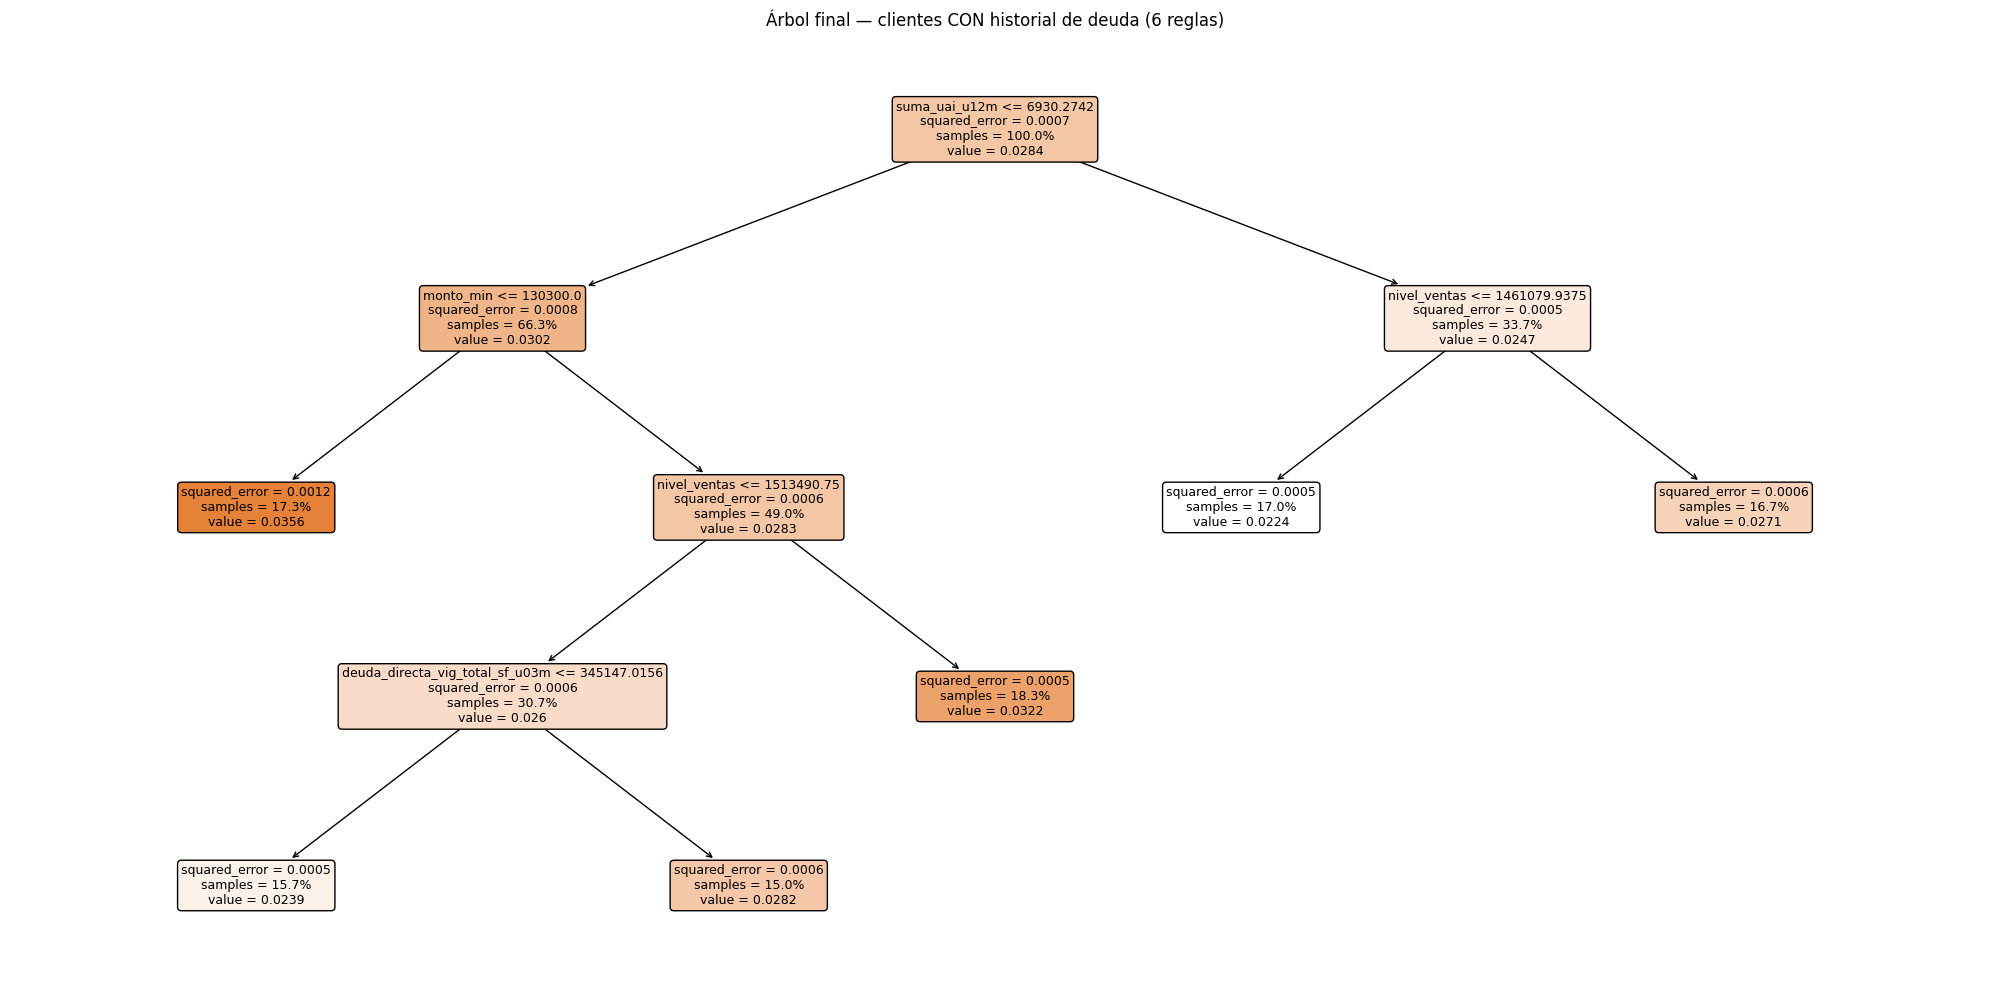

In [49]:
reglas_con_historial = export_text(modelo_con_historial, feature_names=list(X_con_historial.columns), decimals=4)
print(reglas_con_historial)

plt.figure(figsize=(20, 10))
plot_tree(
    modelo_con_historial, feature_names=X_con_historial.columns,
    filled=True, rounded=True, fontsize=9, proportion=True, precision=4,
)
plt.title(f"Árbol final — clientes CON historial de deuda ({modelo_con_historial.get_n_leaves()} reglas)")
plt.tight_layout()
plt.savefig("arbol_con_historial.png", dpi=150)
plt.show()


## 6. Modelo final 2 — árbol de decisión para clientes SIN historial de deuda

In [50]:
modelo_sin_historial, X_sin_historial, y_sin_historial = entrenar_arbol_final(
    df_sin_historial, cols_features, HIPERPARAMETROS_SIN_HISTORIAL,
)


Tamaño de la base: 947 filas
Número de hojas (reglas): 3


|--- pasivosprom_u3m <= 12636.4668
|   |--- nivel_ventas <= 272536.9844
|   |   |--- value: [0.0211]
|   |--- nivel_ventas >  272536.9844
|   |   |--- value: [0.0269]
|--- pasivosprom_u3m >  12636.4668
|   |--- value: [0.0394]



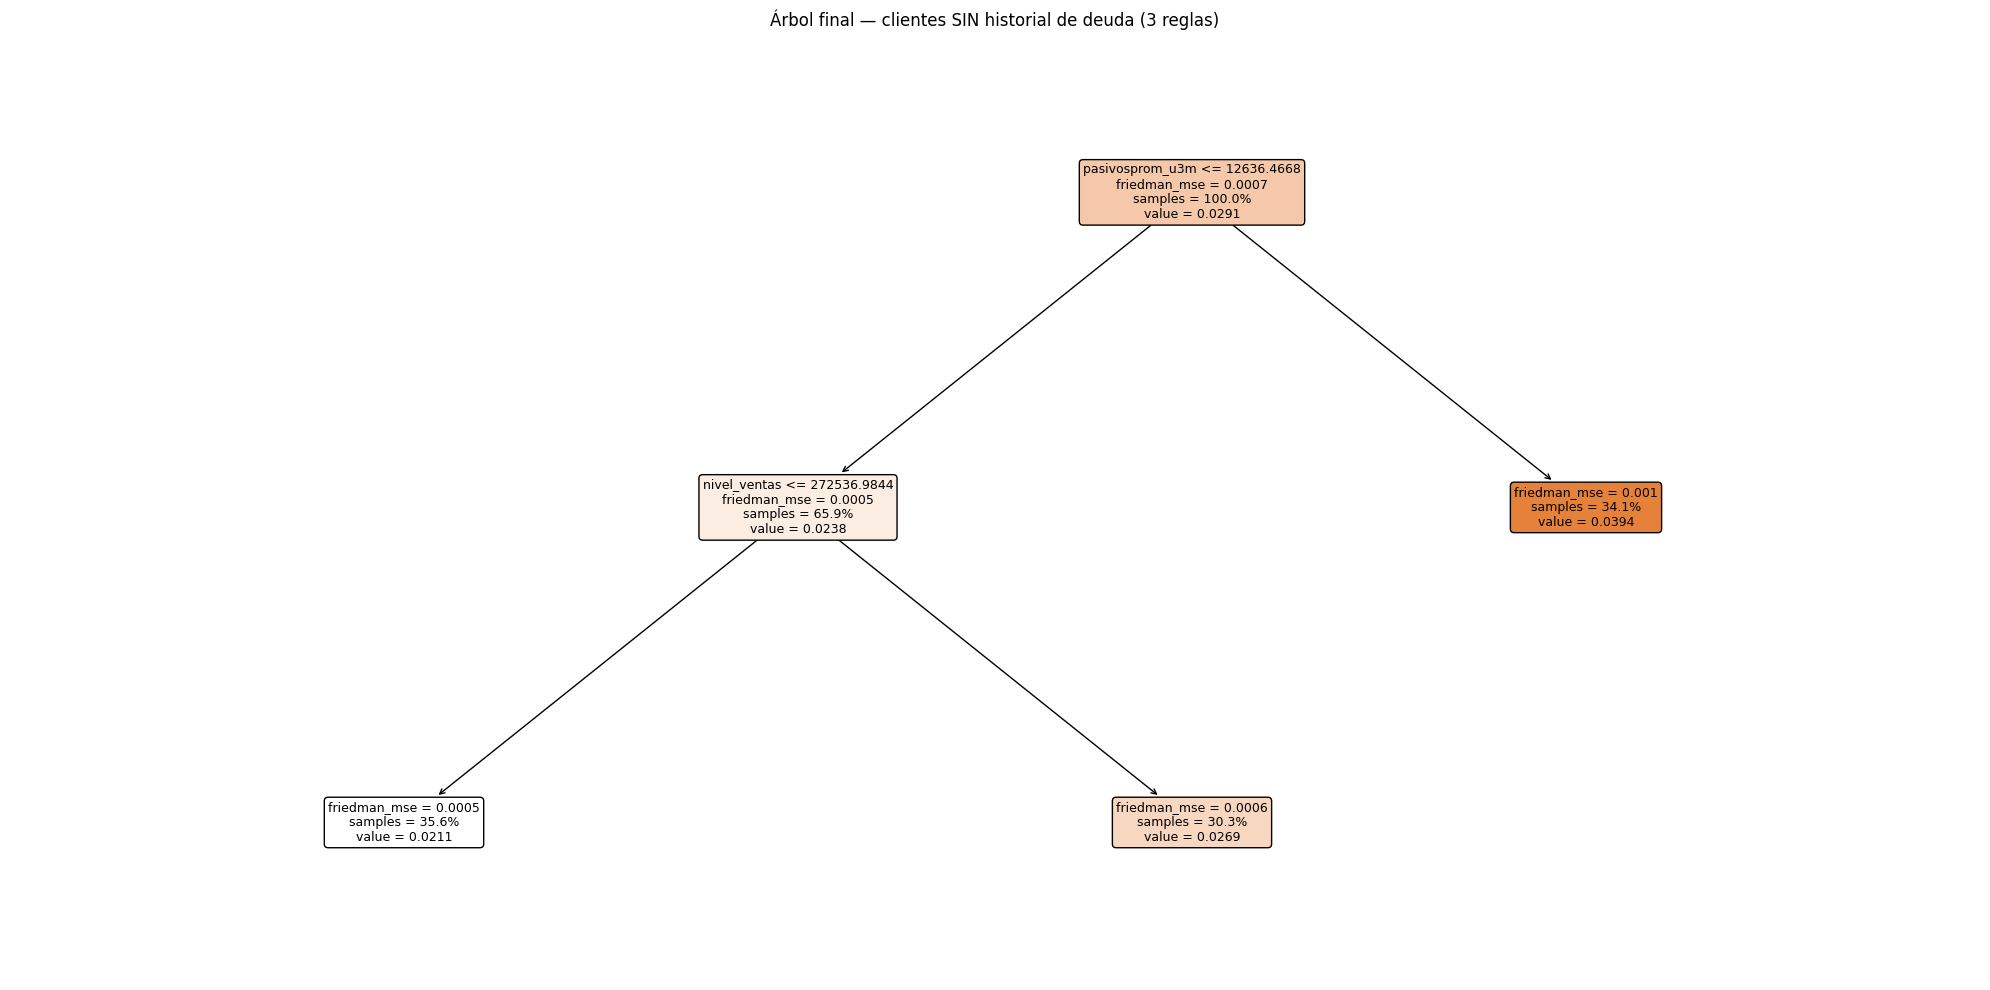

In [51]:
reglas_sin_historial = export_text(modelo_sin_historial, feature_names=list(X_sin_historial.columns), decimals=4)
print(reglas_sin_historial)

plt.figure(figsize=(20, 10))
plot_tree(
    modelo_sin_historial, feature_names=X_sin_historial.columns,
    filled=True, rounded=True, fontsize=9, proportion=True, precision=4,
)
plt.title(f"Árbol final — clientes SIN historial de deuda ({modelo_sin_historial.get_n_leaves()} reglas)")
plt.tight_layout()
plt.savefig("arbol_sin_historial.png", dpi=150)
plt.show()


## 7. Asignación final de clusters (reglas de negocio)
- **Con historial de deuda** (6 hojas → 6 segmentos): separa primero por
  `suma_uai_u12m` (utilidad antes de impuestos), luego por `monto_min` y
  `nivel_ventas`/`deuda_directa_vig_total_sf_u03m`.
- **Sin historial de deuda** (3 hojas → 3 segmentos): separa por
  `pasivosprom_u3m` y `nivel_ventas`.


In [52]:
NOMBRES_CON_HISTORIAL = [  
    "Cliente Ancla",
    "Socio en Crecimiento",
    "Cuenta Estratégica",
    "Maduro Multibanco",
    "Gran Cuenta por Conquistar",
    "Cliente por Reactivar",
]
NOMBRES_SIN_HISTORIAL = [  
    "Emprendedor Izipay",
    "Nuevo en Expansión",
    "Próximo Recurrente",
]
ORDEN_CLUSTERS = NOMBRES_CON_HISTORIAL + NOMBRES_SIN_HISTORIAL


def extraer_reglas(modelo, nombres_variables, nombres_clusters):
    # recorre el árbol y arma la condición de cada hoja como texto
    arbol = modelo.tree_
    hojas = []
    pila = [(0, [])] 
    while pila:
        nodo, condiciones = pila.pop()
        if arbol.children_left[nodo] == arbol.children_right[nodo]:  # es hoja
            hojas.append((float(arbol.value[nodo][0][0]), " & ".join(condiciones)))
            continue
        variable = nombres_variables[arbol.feature[nodo]]
        umbral = float(arbol.threshold[nodo])
        pila.append((arbol.children_right[nodo], condiciones + [f"(`{variable}` > {umbral!r})"]))
        pila.append((arbol.children_left[nodo], condiciones + [f"(`{variable}` <= {umbral!r})"]))

    assert len(hojas) == len(nombres_clusters), "El número de hojas no coincide con el número de nombres"
    hojas = sorted(hojas)  
    return {nombre: regla for nombre, (_, regla) in zip(nombres_clusters, hojas)}


REGLAS_CON_HISTORIAL = extraer_reglas(modelo_con_historial, list(X_con_historial.columns), NOMBRES_CON_HISTORIAL)
REGLAS_SIN_HISTORIAL = extraer_reglas(modelo_sin_historial, list(X_sin_historial.columns), NOMBRES_SIN_HISTORIAL)

for nombre, regla in {**REGLAS_CON_HISTORIAL, **REGLAS_SIN_HISTORIAL}.items():
    print(f"{nombre}: {regla}")


def asignar_cluster(df_entrada):
    tiene_historial = df_entrada["sow_deuda_u12m"].notna()
    condiciones, nombres = [], []
    for nombre, regla in REGLAS_CON_HISTORIAL.items():
        condiciones.append(tiene_historial & df_entrada.eval(regla, engine="python"))
        nombres.append(nombre)
    for nombre, regla in REGLAS_SIN_HISTORIAL.items():
        condiciones.append(~tiene_historial & df_entrada.eval(regla, engine="python"))
        nombres.append(nombre)

    cluster = np.select(condiciones, nombres, default="sin_clasificar")
    return pd.Series(pd.Categorical(cluster, categories=ORDEN_CLUSTERS, ordered=True), index=df_entrada.index)


df["cluster"] = asignar_cluster(df)
print(df["cluster"].value_counts(normalize=True).sort_index() * 100)

Cliente Ancla: (`suma_uai_u12m` > 6930.274169921875) & (`nivel_ventas` <= 1461079.9375)
Socio en Crecimiento: (`suma_uai_u12m` <= 6930.274169921875) & (`monto_min` > 130300.0) & (`nivel_ventas` <= 1513490.75) & (`deuda_directa_vig_total_sf_u03m` <= 345147.015625)
Cuenta Estratégica: (`suma_uai_u12m` > 6930.274169921875) & (`nivel_ventas` > 1461079.9375)
Maduro Multibanco: (`suma_uai_u12m` <= 6930.274169921875) & (`monto_min` > 130300.0) & (`nivel_ventas` <= 1513490.75) & (`deuda_directa_vig_total_sf_u03m` > 345147.015625)
Gran Cuenta por Conquistar: (`suma_uai_u12m` <= 6930.274169921875) & (`monto_min` > 130300.0) & (`nivel_ventas` > 1513490.75)
Cliente por Reactivar: (`suma_uai_u12m` <= 6930.274169921875) & (`monto_min` <= 130300.0)
Emprendedor Izipay: (`pasivosprom_u3m` <= 12636.466796875) & (`nivel_ventas` <= 272536.984375)
Nuevo en Expansión: (`pasivosprom_u3m` <= 12636.466796875) & (`nivel_ventas` > 272536.984375)
Próximo Recurrente: (`pasivosprom_u3m` > 12636.466796875)
cluster
C

## 8. Evolución de la composición de los clusters en el tiempo


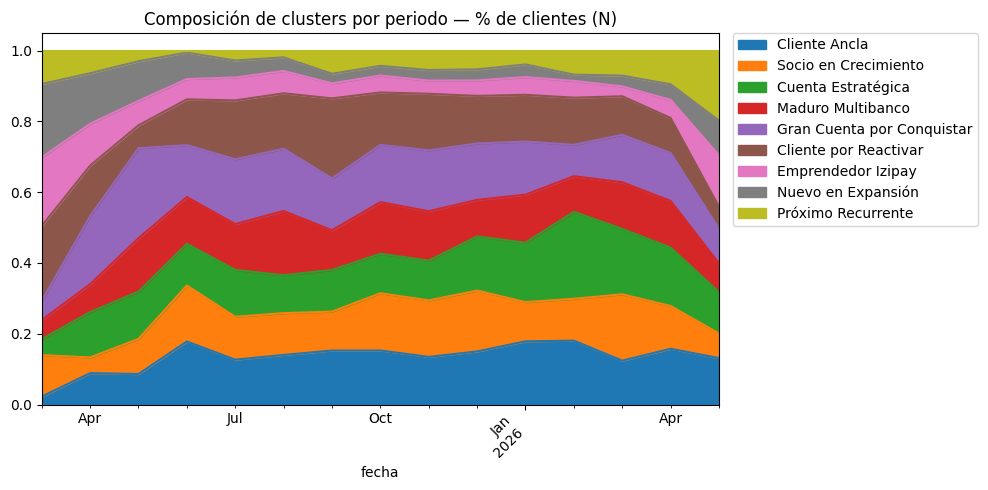

In [53]:
fig, ax = plt.subplots(figsize=(10, 5))
df['fecha'] = pd.to_datetime(df['periodo'], format='%Y%m')

df_n_pct = df.groupby(['fecha'])['cluster'].value_counts(normalize=True).unstack()
df_n_pct.plot(kind='area', ax=ax)

ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
ax.set_title('Composición de clusters por periodo — % de clientes (N)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


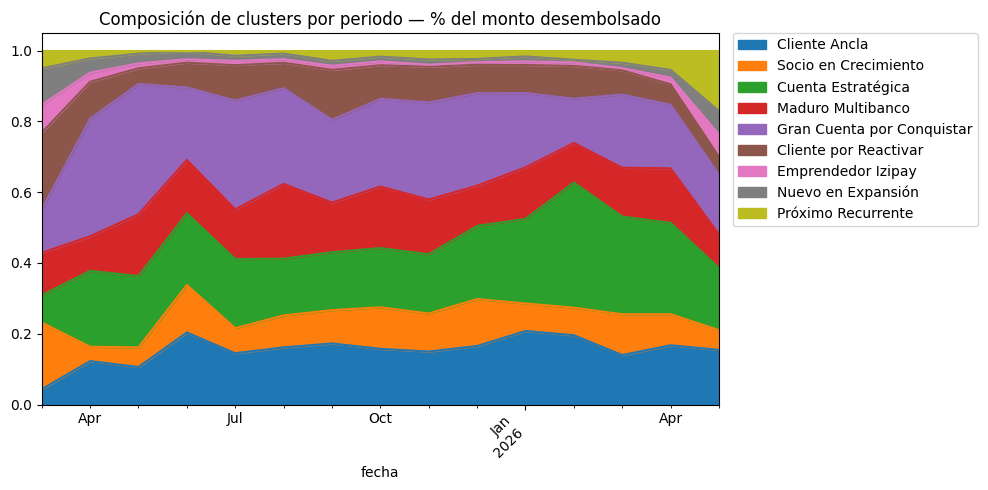

In [54]:
fig, ax = plt.subplots(figsize=(10, 5))

df_vol = df.groupby(['fecha', 'cluster'], observed=True)['monto_desembolsado'].sum().unstack()
df_vol_pct = df_vol.div(df_vol.sum(axis=1), axis=0)  # normaliza cada fila (periodo) a 100%
df_vol_pct.plot(kind='area', ax=ax)

ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
ax.set_title('Composición de clusters por periodo — % del monto desembolsado')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 9. Validación de estabilidad del segmento en el tiempo (PSI)

Se calcula el **PSI (Population Stability Index)** mes a mes, comparando la
distribución de clusters contra la del mes previo

- PSI < 0.10 → estable
- 0.10–0.25 → cambio moderado
- \> 0.25 → cambio significativo


   periodo_actual   ventana_previa    psi        interpretacion
0          202504  202503 a 202503 0.5327  Cambio significativo
1          202505  202504 a 202504 0.2301       Cambio moderado
2          202506  202505 a 202505 0.2606  Cambio significativo
3          202507  202506 a 202506 0.0949               Estable
4          202508  202507 a 202507 0.0305               Estable
5          202509  202508 a 202508 0.1359       Cambio moderado
6          202510  202509 a 202509 0.0734               Estable
7          202511  202510 a 202510 0.0096               Estable
8          202512  202511 a 202511 0.0328               Estable
9          202601  202512 a 202512 0.0484               Estable
10         202602  202601 a 202601 0.1013       Cambio moderado
11         202603  202602 a 202602 0.1194       Cambio moderado
12         202604  202603 a 202603 0.0669               Estable
13         202605  202604 a 202604 0.3210  Cambio significativo


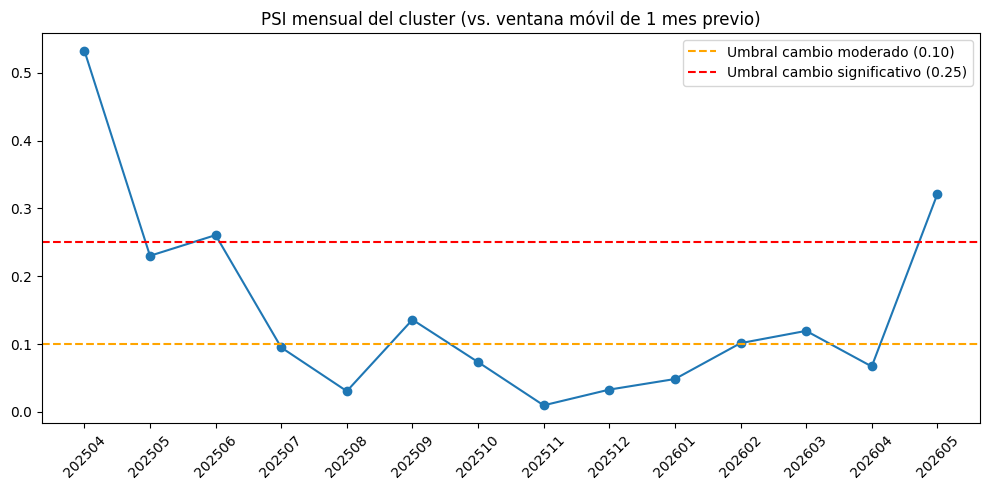

In [55]:
def calcular_psi(esperado: pd.Series, actual: pd.Series, categorias=None, epsilon=1e-4):
    if categorias is None:
        categorias = sorted(set(esperado.unique()) | set(actual.unique()))

    dist_esperado = esperado.value_counts(normalize=True).reindex(categorias, fill_value=0).clip(lower=epsilon)
    dist_actual = actual.value_counts(normalize=True).reindex(categorias, fill_value=0).clip(lower=epsilon)

    psi_por_categoria = (dist_actual - dist_esperado) * np.log(dist_actual / dist_esperado)
    return psi_por_categoria.sum()


def interpretar_psi(psi_total):
    if psi_total < 0.1:
        return "Estable"
    elif psi_total < 0.25:
        return "Cambio moderado"
    else:
        return "Cambio significativo"


df['periodo'] = pd.to_datetime(df['periodo'], format='%Y%m').dt.strftime('%Y%m')

VENTANA = 1  # meses de ventana previa contra la que se compara cada mes
periodos = sorted(df["periodo"].unique())
categorias_cluster = sorted(df["cluster"].unique())

resultados_psi = []
for i in range(VENTANA, len(periodos)):
    periodo_actual = periodos[i]
    ventana_previa = periodos[i - VENTANA:i]

    dist_previa = df.loc[df["periodo"].isin(ventana_previa), "cluster"]
    dist_actual = df.loc[df["periodo"] == periodo_actual, "cluster"]
    psi_total = calcular_psi(dist_previa, dist_actual, categorias=categorias_cluster)

    resultados_psi.append({
        "periodo_actual": periodo_actual,
        "ventana_previa": f"{ventana_previa[0]} a {ventana_previa[-1]}",
        "psi": round(psi_total, 4),
        "interpretacion": interpretar_psi(psi_total),
    })

tabla_psi = pd.DataFrame(resultados_psi)
print(tabla_psi)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tabla_psi["periodo_actual"].astype(str), tabla_psi["psi"], marker="o")
ax.axhline(0.1, color="orange", linestyle="--", label="Umbral cambio moderado (0.10)")
ax.axhline(0.25, color="red", linestyle="--", label="Umbral cambio significativo (0.25)")
ax.legend()
plt.xticks(rotation=45)
plt.title("PSI mensual del cluster (vs. ventana móvil de 1 mes previo)")
plt.tight_layout()
plt.savefig("psi_ventana_movil.png", dpi=150)
plt.show()


## 10. Perfil de los clusters

Comparación visual de las variables más relevantes entre segmentos

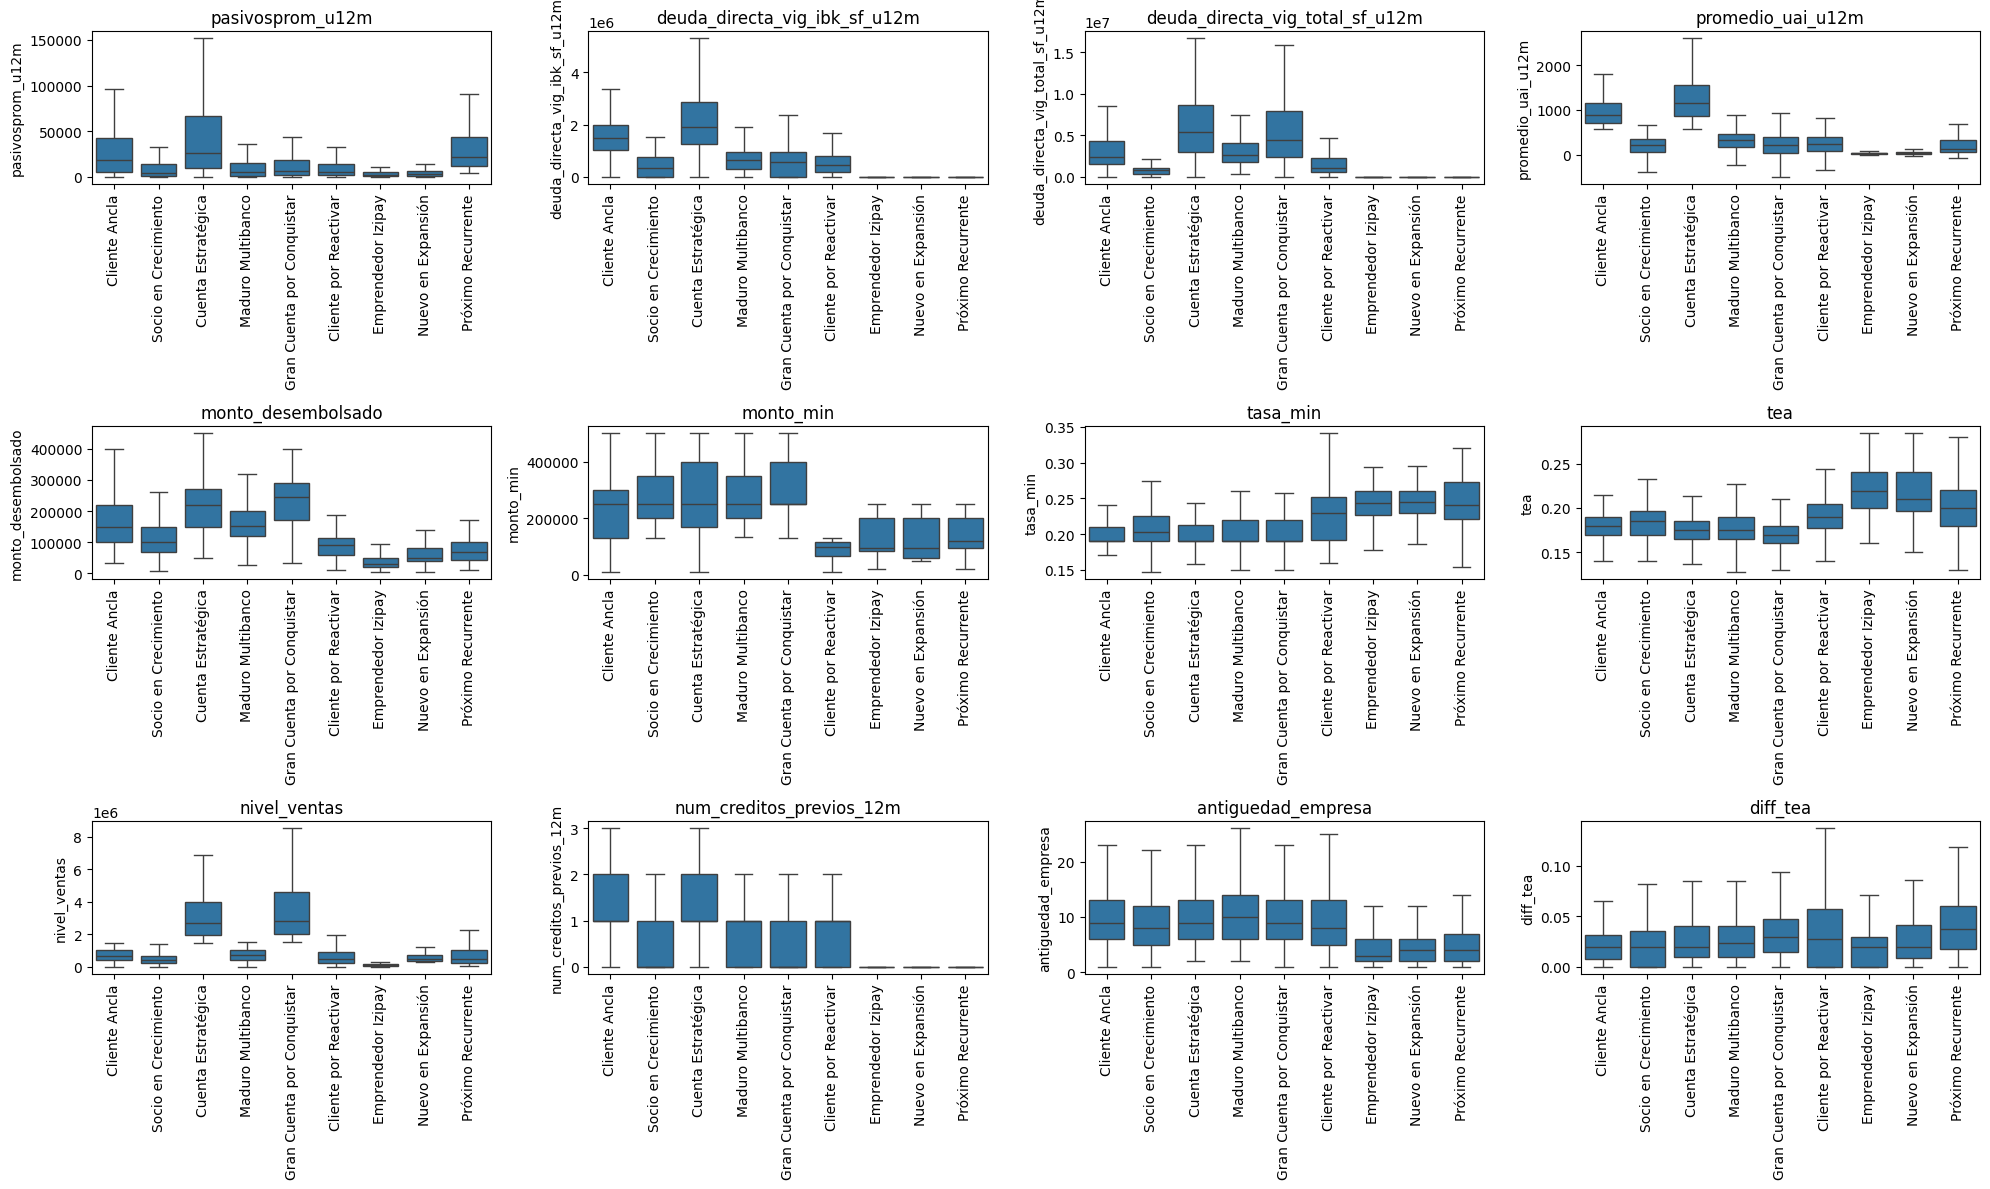

In [56]:
cols_perfil = [
    'pasivosprom_u12m', 'deuda_directa_vig_ibk_sf_u12m', 'deuda_directa_vig_total_sf_u12m',
    'promedio_uai_u12m', 'monto_desembolsado', 'monto_min', 'tasa_min', 'tea',
    'nivel_ventas', 'num_creditos_previos_12m', 'antiguedad_empresa', 'diff_tea',
]

n_cols = 4
n_rows = math.ceil(len(cols_perfil) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols_perfil):
    sns.boxplot(data=df, x='cluster', y=col, ax=axes[i], showfliers=False)
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=90)

for j in range(len(cols_perfil), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


## 11. Tabla resumen final por cluster 

Tabla consolidada con las métricas principales de cada cluster

In [57]:
# Tramo del descuento de tasa
df['diff_tea_pb'] = (df['diff_tea'] * 10000).round(0)
bins_tramo = [-1, 0, 200, 400, np.inf]
labels_tramo = ['Sin Descuento', '(0-200]', '(200-400]', '(400+]']
df['tramo_diff_tea'] = pd.cut(df['diff_tea_pb'], bins=bins_tramo, labels=labels_tramo)


In [58]:
total_clientes = len(df)
total_desembolso = df['monto_desembolsado'].sum()

suma_cluster_periodo = (
    df.groupby(['cluster', 'periodo'])['monto_desembolsado'].sum().unstack('periodo').fillna(0)
)
monto_promedio_periodo = suma_cluster_periodo.mean(axis=1)
promedio_total_periodo = df.groupby('periodo')['monto_desembolsado'].sum().mean()
monto_promedio_periodo_pct = monto_promedio_periodo / promedio_total_periodo * 100

resumen = df.groupby('cluster').agg(
    tea_prom_ponderado=('tea', lambda x: np.average(x, weights=df.loc[x.index, 'monto_desembolsado'])),
    tea_oferta_prom_ponderado=('tasa_min', lambda x: np.average(x, weights=df.loc[x.index, 'monto_desembolsado'])),
    clientes_n=('cluster', 'size'),
    monto_desemb_mediana=('monto_desembolsado', 'median'),
    antiguedad_empresa_mediana=('antiguedad_empresa', 'median'),
    ventas_mediana=('nivel_ventas', 'median'),
    pasivos_prom_mediana=('pasivosprom_u12m', 'median'),
    uai_prom_mediana=('promedio_uai_u12m', 'median'),
    sow_deuda_mediana=('sow_deuda_u12m', 'median'),
    retanqueo_pct=('flg_retanqueo', 'mean'),
    cliente_izipay_pct=('flg_cliente_izipay', 'mean'),
)
resumen['clientes_pct'] = resumen['clientes_n'] / total_clientes * 100
resumen['part_desembolso_pct'] = df.groupby('cluster')['monto_desembolsado'].sum() / total_desembolso * 100
resumen['retanqueo_pct'] *= 100
resumen['cliente_izipay_pct'] *= 100
resumen['monto_promedio_periodo'] = monto_promedio_periodo.reindex(resumen.index)
resumen['monto_promedio_periodo_pct'] = monto_promedio_periodo_pct.reindex(resumen.index)
resumen = resumen.round(4)

composicion_abc = (pd.crosstab(df['cluster'], df['segmento_abc'], normalize='index') * 100).round(1)
composicion_dcto = (pd.crosstab(df['cluster'], df['tramo_diff_tea'], normalize='index') * 100).round(1)
composicion_abc_monto_pct = (pd.crosstab(
    df['cluster'], df['segmento_abc'], values=df['monto_desembolsado'], aggfunc='sum', normalize='index'
) * 100).round(1)
composicion_dcto_monto_pct = (pd.crosstab(
    df['cluster'], df['tramo_diff_tea'], values=df['monto_desembolsado'], aggfunc='sum', normalize='index'
) * 100).round(1)

tabla_final = pd.concat(
    [
        resumen.T,
        composicion_abc.T.rename(index=lambda x: f'ABC_{x}'),
        composicion_abc_monto_pct.T.rename(index=lambda x: f'ABC_MONTO_PCT_{x}'),
        composicion_dcto.T.rename(index=lambda x: f'DCTO_{x}'),
        composicion_dcto_monto_pct.T.rename(index=lambda x: f'DCTO_MONTO_PCT_{x}'),
    ],
    axis=0,
    keys=['Métricas', 'Segmento ABC - N', 'Segmento ABC - Monto %', 'Tramo Dcto Tasa - N', 'Tramo Dcto Tasa - Monto %'],
)

print("Tabla resumen final por cluster:")
tabla_final


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_32476\36985960.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['cluster', 'periodo'])['monto_desembolsado'].sum().unstack('periodo').fillna(0)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_32476\36985960.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumen = df.groupby('cluster').agg(
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_32476\36985960.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the 

Tabla resumen final por cluster:


cluster                                                 Cliente Ancla  \
Métricas                  tea_prom_ponderado                   0.1766   
                          tea_oferta_prom_ponderado            0.2004   
                          clientes_n                         707.0000   
                          monto_desemb_mediana           150,007.5000   
                          antiguedad_empresa_mediana           9.0000   
                          ventas_mediana                 682,251.0000   
                          pasivos_prom_mediana            18,698.9714   
                          uai_prom_mediana                   890.9322   
                          sow_deuda_mediana                    0.6788   
                          retanqueo_pct                       18.5290   
                          cliente_izipay_pct                  38.0481   
                          clientes_pct                        13.8437   
                          part_desembolso_pct                 15.9435   
                          monto_promedio_periodo       8,120,892.3693   
                          monto_promedio_periodo_pct          15.9435   
Segmento ABC - N          ABC_A                               97.9000   
                          ABC_B                                2.1000   
                          ABC_C                                0.0000   
Segmento ABC - Monto %    ABC_MONTO_PCT_A                     98.0000   
                          ABC_MONTO_PCT_B                      2.0000   
                          ABC_MONTO_PCT_C                      0.0000   
Tramo Dcto Tasa - N       DCTO_Sin Descuento                  22.8000   
                          DCTO_(0-200]                        36.2000   
                          DCTO_(200-400]                      24.6000   
                          DCTO_(400+]                         16.4000   
Tramo Dcto Tasa - Monto % DCTO_MONTO_PCT_Sin Descuento        18.1000   
                          DCTO_MONTO_PCT_(0-200]              37.5000   
                          DCTO_MONTO_PCT_(200-400]            27.3000   
                          DCTO_MONTO_PCT_(400+]               17.1000   

cluster                                                 Socio en Crecimiento  \
Métricas                  tea_prom_ponderado                          0.1813   
                          tea_oferta_prom_ponderado                   0.2053   
                          clientes_n                                653.0000   
                          monto_desemb_mediana                  100,005.0000   
                          antiguedad_empresa_mediana                  8.0000   
                          ventas_mediana                        443,754.7200   
                          pasivos_prom_mediana                    4,083.0242   
                          uai_prom_mediana                          203.5417   
                          sow_deuda_mediana                           0.5552   
                          retanqueo_pct                               6.4319   
                          cliente_izipay_pct                         35.5283   
                          clientes_pct                               12.7864   
                          part_desembolso_pct                         9.4499   
                          monto_promedio_periodo              4,813,358.5880   
                          monto_promedio_periodo_pct                  9.4499   
Segmento ABC - N          ABC_A                                      26.6000   
                          ABC_B                                      62.6000   
                          ABC_C                                      10.7000   
Segmento ABC - Monto %    ABC_MONTO_PCT_A                            33.5000   
                          ABC_MONTO_PCT_B                            59.2000   
                          ABC_MONTO_PCT_C                             7.4000   
Tramo Dcto Tasa - N       DCTO_Sin Descuento     

## 12. Data Actualizada

Esta sección aplica la segmentación ya construida a la versión actualizada de la tabla de clientes, sobre los mismos desembolsos de las secciones 1 y 2 (`df_copy`). Los árboles **no se reentrenan**: se usan las reglas de la sección 7, y tanto las imputaciones como los cortes del SOW reutilizan los valores calculados sobre `df`. De este modo, cualquier diferencia con la segmentación original proviene únicamente de la actualización de las variables del cliente.

### 12.1 Cruce con las variables actualizadas

La tabla de clientes se lee dos veces desde el mismo archivo, una con las variables cliente y otra con las variables de deuda del RCC, porque cada grupo se cruza con un desfase distinto. Las **variables cliente** (ventas, pasivos, utilidad, Izipay) se toman del **mes anterior** al desembolso, igual que en la sección 3. Las **variables del RCC** se cruzan con el **mismo `codmes`** del desembolso, ya que ya tienen integrado el rezago de dos meses.

In [59]:
ruta_clientes_actual = r"C:/Users/Lenovo/Streaming de Google Drive/.shortcut-targets-by-id/14G2D9-Gte-83zSj-crVkwplKt-CX4FE6/11_IBK BdN Cliente360/01_ Solicitud Datos/Tablon_Unificado/06_Clientes/mr_voi_tabla_clientes_V04.csv"

cols_clientes_actual = [
    'codmes', 'key_value', 'segmento_abc', 'sei_mcdo', 'departamento',
    'antiguedad_empresa', 'nivel_ventas',
    'pasivosprom_u3m', 'pasivosprom_u6m', 'pasivosprom_u12m',
    'salprom_creditos_u03m', 'salprom_creditos_u06m', 'salprom_creditos_u12m',
    'antiguedad_izipay',
    'flag_izipay_u03m', 'flag_izipay_u06m', 'flag_izipay_u12m',
    'vol_izipay_u03m', 'vol_izipay_u06m', 'vol_izipay_u12m',
    'suma_uai_u12m', 'promedio_uai_u12m',
]

cols_rcc_actual = [
    'codmes', 'key_value',
    'deuda_directa_vig_ibk_sf_u03m', 'deuda_directa_vig_ibk_sf_u06m', 'deuda_directa_vig_ibk_sf_u12m',
    'deuda_directa_vig_total_sf_u03m', 'deuda_directa_vig_total_sf_u06m', 'deuda_directa_vig_total_sf_u12m',
    'avg_deuda_directa_vig_ibk_sf_u03m', 'avg_deuda_directa_vig_ibk_sf_u06m', 'avg_deuda_directa_vig_ibk_sf_u12m',
    'avg_deuda_directa_vig_total_sf_u03m', 'avg_deuda_directa_vig_total_sf_u06m', 'avg_deuda_directa_vig_total_sf_u12m',
]

df_vars_v2_clientes = pd.read_csv(ruta_clientes_actual, usecols=cols_clientes_actual, encoding='latin-1', na_values=[r'\N'])
df_vars_v2_rcc = pd.read_csv(ruta_clientes_actual, usecols=cols_rcc_actual, encoding='latin-1', na_values=[r'\N'])
df_vars_v2_clientes = df_vars_v2_clientes.drop_duplicates(subset=['key_value', 'codmes'])
df_vars_v2_rcc = df_vars_v2_rcc.drop_duplicates(subset=['key_value', 'codmes'])

In [60]:
# Variables cliente: foto del mes anterior al desembolso (codmes + 1 = periodo del desembolso)
df_vars_v2_clientes['codmes_2'] = (
    pd.to_datetime(df_vars_v2_clientes['codmes'].astype(str), format='%Y%m') + pd.DateOffset(months=1)
).dt.strftime('%Y%m').astype(int)
df_vars_v2_clientes['llave_interna'] = df_vars_v2_clientes['key_value'] + "-" + df_vars_v2_clientes['codmes_2'].astype(str)

# RCC: mismo mes del desembolso, sin rezago adicional
df_vars_v2_rcc['llave_interna'] = df_vars_v2_rcc['key_value'] + "-" + df_vars_v2_rcc['codmes'].astype(str)

# Base = variables cliente; el RCC se agrega con left para no perder clientes sin registro en el RCC
df_vars_final = df_vars_v2_clientes.merge(
    df_vars_v2_rcc.drop(columns=['codmes', 'key_value']), on='llave_interna', how='left'
)

print(f"Antes del cruce: {df_copy.shape}")
df_actual = pd.merge(df_copy, df_vars_final.drop(columns=['key_value']), on='llave_interna', how='left')
print(f"Después del cruce: {df_actual.shape}")

# Desembolsos sin foto de variables cliente
print(f"\nAntes del filtro cliente: {df_actual.shape}")
df_sin_variables_actual = df_actual[df_actual['codmes_2'].isna()]
df_actual = df_actual[df_actual['codmes_2'].notna()]
print(f"Después del filtro cliente: {df_actual.shape}")
print(f"Desembolsos sin deuda reportada en el RCC del mes: {df_actual['deuda_directa_vig_total_sf_u12m'].isna().sum():,}")

Antes del cruce: (8216, 29)
Después del cruce: (8216, 63)

Antes del filtro cliente: (8216, 63)
Después del filtro cliente: (5575, 63)
Desembolsos sin deuda reportada en el RCC del mes: 1,265


### 12.2 Tratamiento de missings y feature engineering

Se aplican los mismos tratamientos de las secciones 3 y 4, pero con los valores calculados sobre `df`.

In [64]:
# Imputación con 0: ausencia de producto o saldo
cols_fill_zero_actual = [
    'pasivosprom_u3m', 'pasivosprom_u6m', 'pasivosprom_u12m',
    'salprom_creditos_u03m', 'salprom_creditos_u06m', 'salprom_creditos_u12m',
    'deuda_directa_vig_ibk_sf_u03m', 'deuda_directa_vig_ibk_sf_u06m', 'deuda_directa_vig_ibk_sf_u12m',
    'deuda_directa_vig_total_sf_u03m', 'deuda_directa_vig_total_sf_u06m', 'deuda_directa_vig_total_sf_u12m',
    'suma_uai_u12m', 'promedio_uai_u12m',
]
df_actual[cols_fill_zero_actual] = df_actual[cols_fill_zero_actual].fillna(0)

df_actual = df_actual.drop(columns=['codmes', 'codmes_2'], errors='ignore')

# Imputación con la moda y la mediana calculadas sobre df (no se recalculan)
cols_moda = ['departamento', 'segmento_abc', 'sei_mcdo', 'antiguedad_empresa']
for col in cols_moda:
    moda = valores_imputacion[col]
    n_missing = df_actual[col].isna().sum()
    df_actual[col] = df_actual[col].fillna(moda)
    print(f"'{col}': {n_missing:,} missings imputados con la moda de df ({moda})")

n_missing = df_actual['nivel_ventas'].isna().sum()
df_actual['nivel_ventas'] = df_actual['nivel_ventas'].fillna(mediana_ventas)
print(f"'nivel_ventas': {n_missing:,} missings imputados con la mediana de df ({mediana_ventas:,.0f})")

df_temp = df_actual.isna().mean().reset_index(name='missings')
print("\nColumnas que aún tienen missings:")
print(df_temp[df_temp.missings > 0].sort_values(by='missings'))

'departamento': 1 missings imputados con la moda de df (LIMA)
'segmento_abc': 6 missings imputados con la moda de df (A)
'sei_mcdo': 1 missings imputados con la moda de df (COMERCIO)
'antiguedad_empresa': 1 missings imputados con la moda de df (4.0)
'nivel_ventas': 5 missings imputados con la mediana de df (742,772)

Columnas que aún tienen missings:
                                  index  missings
55    avg_deuda_directa_vig_ibk_sf_u03m    0.2269
56    avg_deuda_directa_vig_ibk_sf_u06m    0.2269
57    avg_deuda_directa_vig_ibk_sf_u12m    0.2269
58  avg_deuda_directa_vig_total_sf_u03m    0.2269
59  avg_deuda_directa_vig_total_sf_u06m    0.2269
60  avg_deuda_directa_vig_total_sf_u12m    0.2269
40                    antiguedad_izipay    0.6204


In [65]:
# SOW de deuda 
for ventana in ['u03m', 'u06m', 'u12m']:
    df_actual[f'sow_deuda_{ventana}'] = (
        df_actual[f'deuda_directa_vig_ibk_sf_{ventana}'] / df_actual[f'deuda_directa_vig_total_sf_{ventana}']
    ).replace([np.inf, -np.inf], np.nan)  

df_actual['flg_cliente_izipay'] = np.where(df_actual['antiguedad_izipay'].isna(), 0, 1)
df_actual['diff_tea'] = df_actual['tasa_min'] - df_actual['tea']
print(f"Clientes sin historial de deuda (SOW u12m vacío): {df_actual['sow_deuda_u12m'].isna().sum():,}")

# Rangos de SOW con los cortes de df
for ventana, bins in cortes_sow.items():
    col_rango = f'rango_sow_{ventana}'
    df_actual[col_rango] = pd.cut(df_actual[f'sow_deuda_{ventana}'], bins=bins, labels=ETIQUETAS_SOW)
    df_actual[col_rango] = df_actual[col_rango].astype(object).fillna('NULO')  
# Filtro de inconsistencias
print(f"\nAntes de filtrar diff_tea >= 0: {df_actual.shape}")
df_actual = df_actual[df_actual['diff_tea'] >= 0]
print(f"Después: {df_actual.shape}")

df_actual = df_actual.drop(columns=['canal_final_copy'], errors='ignore')

cols_dummies = ['sei_mcdo', 'departamento', 'rango_sow_u12m', 'rango_sow_u03m', 'rango_sow_u06m']
df_actual = pd.get_dummies(df_actual, columns=cols_dummies, drop_first=False, dtype=int)

df_actual = df_actual.reset_index(drop=True) 

Clientes sin historial de deuda (SOW u12m vacío): 1,265

Antes de filtrar diff_tea >= 0: (5575, 69)
Después: (5107, 69)


### 12.3 Asignación de clusters

Se aplican las reglas de la sección 7 con `asignar_cluster`.

In [66]:
print(f"Clientes CON historial de deuda: {df_actual['sow_deuda_u12m'].notna().sum():,} (original: {df['sow_deuda_u12m'].notna().sum():,})")
print(f"Clientes SIN historial de deuda: {df_actual['sow_deuda_u12m'].isna().sum():,} (original: {df['sow_deuda_u12m'].isna().sum():,})")

df_actual['cluster'] = asignar_cluster(df_actual)
print(f"Clientes sin clasificar: {df_actual['cluster'].isna().sum():,}")

# Distribución por cluster: original vs. data actualizada
comparativo_clusters = pd.DataFrame({
    'original_pct': df['cluster'].value_counts(normalize=True).sort_index() * 100,
    'actual_pct': df_actual['cluster'].value_counts(normalize=True).sort_index() * 100,
})
comparativo_clusters['diferencia_pp'] = comparativo_clusters['actual_pct'] - comparativo_clusters['original_pct']
print("\nDistribución de clientes por cluster (%):")
print(comparativo_clusters.round(2))

Clientes CON historial de deuda: 4,017 (original: 4,160)
Clientes SIN historial de deuda: 1,090 (original: 947)
Clientes sin clasificar: 0

Distribución de clientes por cluster (%):
                            original_pct  actual_pct  diferencia_pp
cluster                                                            
Cliente Ancla                    13.8400     13.7500        -0.1000
Socio en Crecimiento             12.7900     11.7300        -1.0600
Cuenta Estratégica               13.6100     13.4700        -0.1400
Maduro Multibanco                12.2600     11.6100        -0.6500
Gran Cuenta por Conquistar       14.8800     14.6100        -0.2700
Cliente por Reactivar            14.0800     13.4900        -0.5900
Emprendedor Izipay                6.6000      7.2600         0.6700
Nuevo en Expansión                5.6200      6.7800         1.1600
Próximo Recurrente                6.3200      7.3000         0.9800


### 12.4 Evolución y estabilidad con la data actualizada

Se repiten los gráficos de composición de la sección 8 y el PSI de la sección 9 sobre la data actualizada, para verificar que la estabilidad de los clusters en el tiempo se mantiene.

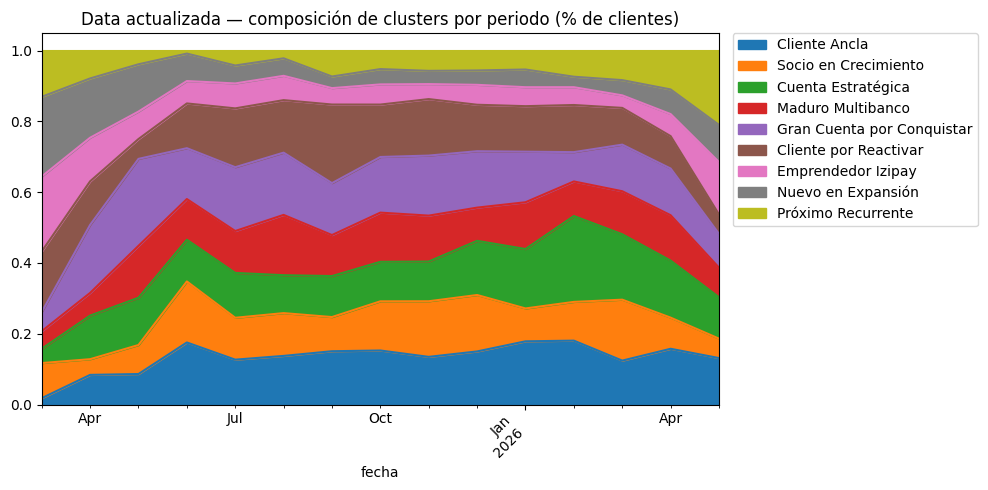

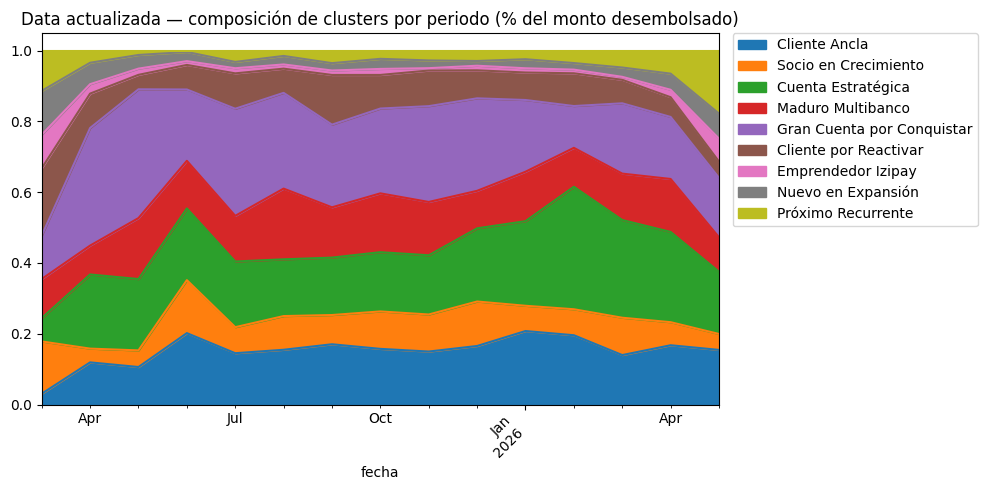

In [67]:
df_actual['fecha'] = pd.to_datetime(df_actual['periodo'], format='%Y%m')

# Composición por número de clientes
fig, ax = plt.subplots(figsize=(10, 5))
df_n_pct_actual = df_actual.groupby('fecha')['cluster'].value_counts(normalize=True).unstack()
df_n_pct_actual.plot(kind='area', ax=ax)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
ax.set_title('Data actualizada — composición de clusters por periodo (% de clientes)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Composición por monto desembolsado
fig, ax = plt.subplots(figsize=(10, 5))
df_vol_actual = df_actual.groupby(['fecha', 'cluster'], observed=True)['monto_desembolsado'].sum().unstack()
df_vol_pct_actual = df_vol_actual.div(df_vol_actual.sum(axis=1), axis=0)  # normaliza cada periodo a 100%
df_vol_pct_actual.plot(kind='area', ax=ax)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
ax.set_title('Data actualizada — composición de clusters por periodo (% del monto desembolsado)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

   periodo_actual   ventana_previa    psi        interpretacion  psi_original
0          202504  202503 a 202503 0.5227  Cambio significativo        0.5327
1          202505  202504 a 202504 0.2154       Cambio moderado        0.2301
2          202506  202505 a 202505 0.3311  Cambio significativo        0.2606
3          202507  202506 a 202506 0.1217       Cambio moderado        0.0949
4          202508  202507 a 202507 0.0386               Estable        0.0305
5          202509  202508 a 202508 0.1409       Cambio moderado        0.1359
6          202510  202509 a 202509 0.0627               Estable        0.0734
7          202511  202510 a 202510 0.0125               Estable        0.0096
8          202512  202511 a 202511 0.0364               Estable        0.0328
9          202601  202512 a 202512 0.0595               Estable        0.0484
10         202602  202601 a 202601 0.0911               Estable        0.1013
11         202603  202602 a 202602 0.1118       Cambio moderado 

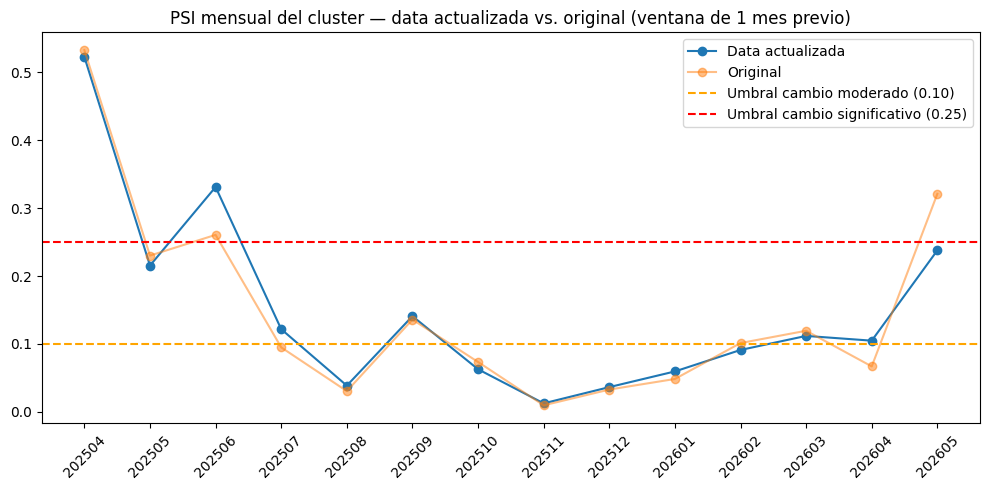

In [68]:
df_actual['periodo'] = pd.to_datetime(df_actual['periodo'], format='%Y%m').dt.strftime('%Y%m')

VENTANA = 1  # meses de ventana previa contra la que se compara cada mes
periodos = sorted(df_actual['periodo'].unique())
categorias_cluster = list(df_actual['cluster'].cat.categories)

resultados_psi_actual = []
for i in range(VENTANA, len(periodos)):
    periodo_actual = periodos[i]
    ventana_previa = periodos[i - VENTANA:i]

    dist_previa = df_actual.loc[df_actual['periodo'].isin(ventana_previa), 'cluster']
    dist_actual = df_actual.loc[df_actual['periodo'] == periodo_actual, 'cluster']
    psi_total = calcular_psi(dist_previa, dist_actual, categorias=categorias_cluster)

    resultados_psi_actual.append({
        'periodo_actual': periodo_actual,
        'ventana_previa': f"{ventana_previa[0]} a {ventana_previa[-1]}",
        'psi': round(psi_total, 4),
        'interpretacion': interpretar_psi(psi_total),
    })

tabla_psi_actual = pd.DataFrame(resultados_psi_actual)
tabla_psi_actual['psi_original'] = tabla_psi_actual['periodo_actual'].map(tabla_psi.set_index('periodo_actual')['psi'])  # PSI de la sección 9
print(tabla_psi_actual)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tabla_psi_actual['periodo_actual'].astype(str), tabla_psi_actual['psi'], marker='o', label='Data actualizada')
ax.plot(tabla_psi_actual['periodo_actual'].astype(str), tabla_psi_actual['psi_original'], marker='o', alpha=0.5, label='Original')
ax.axhline(0.1, color='orange', linestyle='--', label='Umbral cambio moderado (0.10)')
ax.axhline(0.25, color='red', linestyle='--', label='Umbral cambio significativo (0.25)')
ax.legend()
plt.xticks(rotation=45)
plt.title('PSI mensual del cluster — data actualizada vs. original (ventana de 1 mes previo)')
plt.tight_layout()
plt.savefig('psi_ventana_movil_actual.png', dpi=150)
plt.show()

### 12.5 Perfil y tabla resumen con la data actualizada

Se repiten el perfil de la sección 10 y la tabla resumen de la sección 11 sobre la data actualizada.

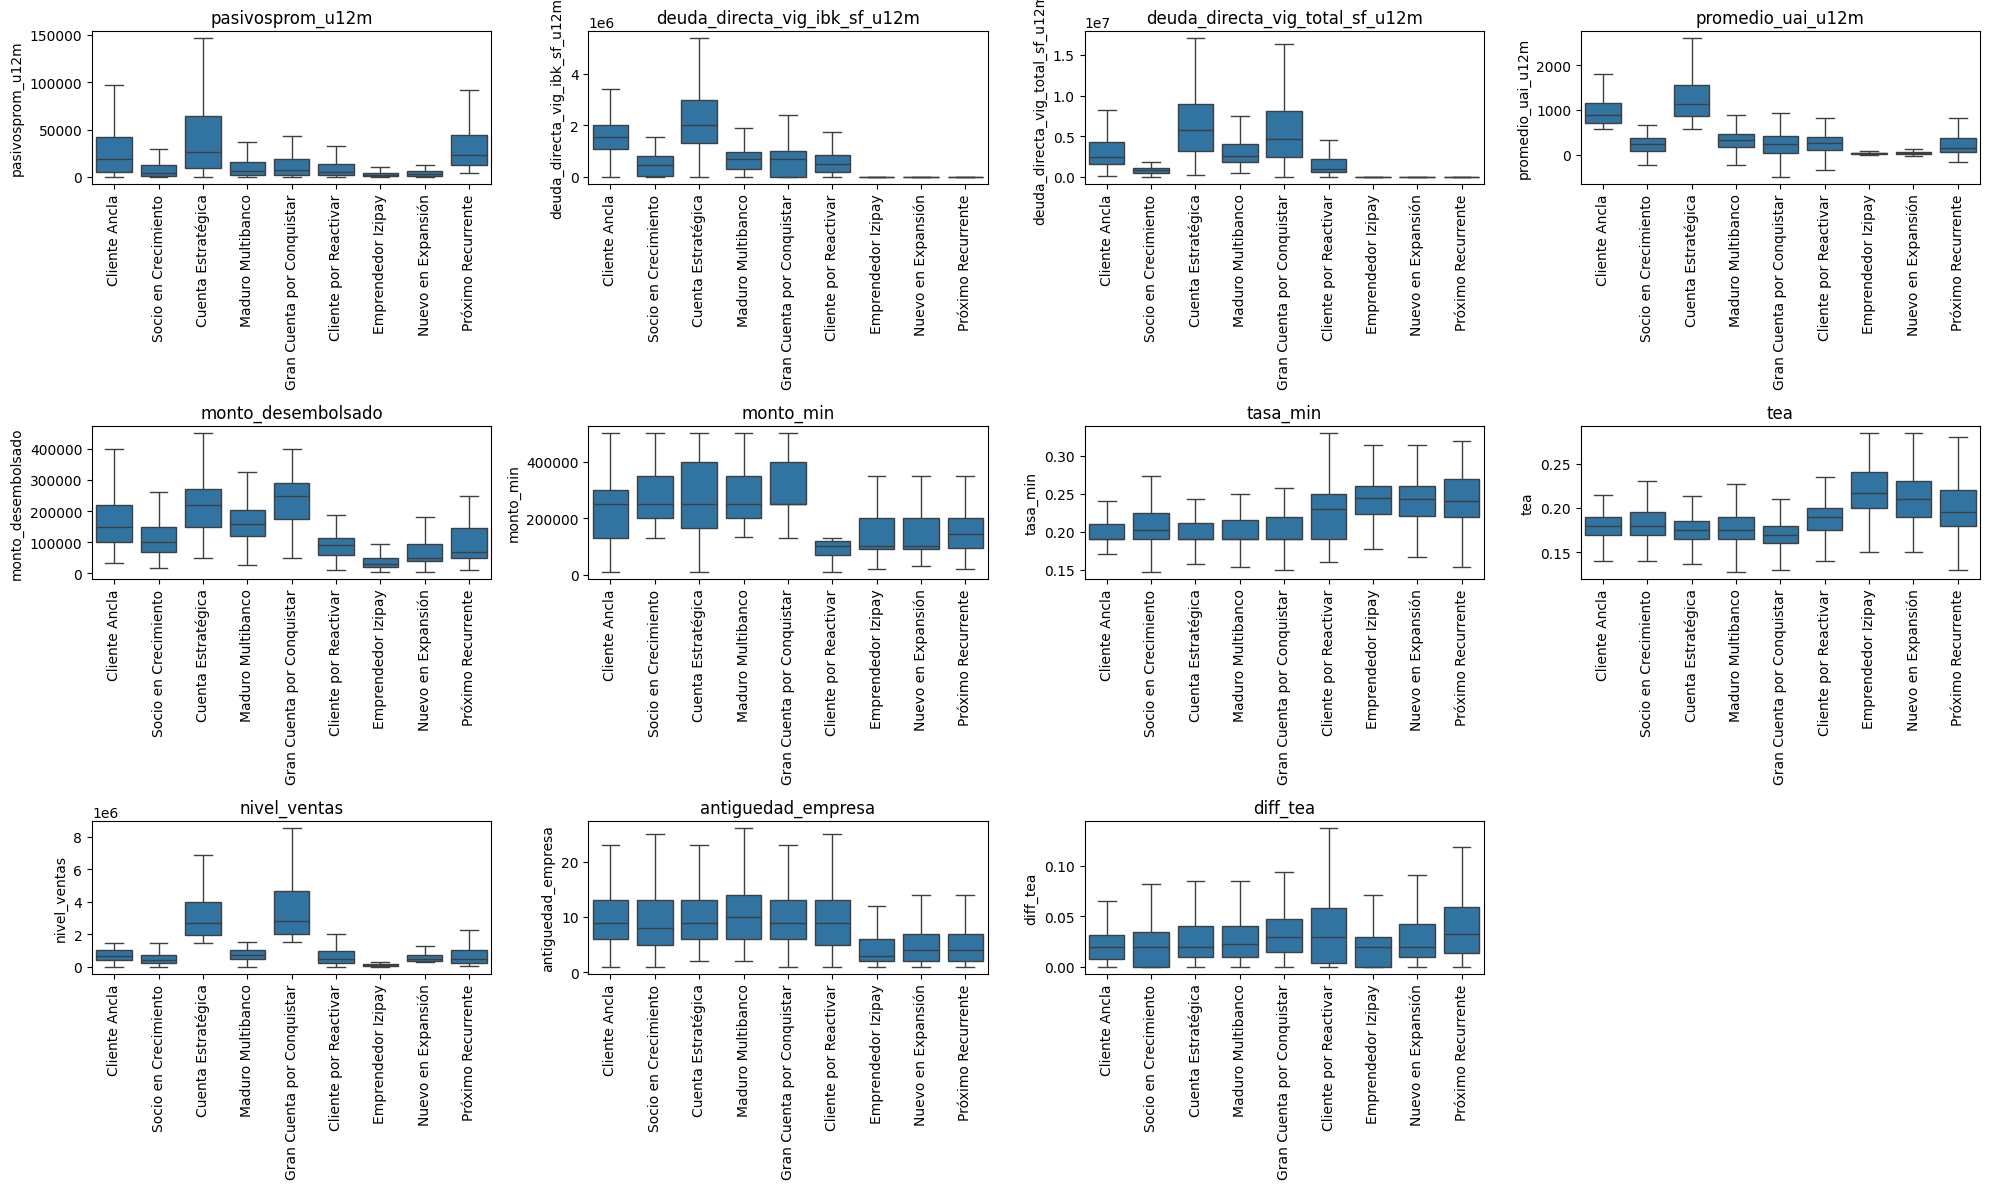

In [69]:
cols_perfil_actual = [
    'pasivosprom_u12m', 'deuda_directa_vig_ibk_sf_u12m', 'deuda_directa_vig_total_sf_u12m',
    'promedio_uai_u12m', 'monto_desembolsado', 'monto_min', 'tasa_min', 'tea',
    'nivel_ventas', 'antiguedad_empresa', 'diff_tea',
]

n_cols = 4
n_rows = math.ceil(len(cols_perfil_actual) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols_perfil_actual):
    sns.boxplot(data=df_actual, x='cluster', y=col, ax=axes[i], showfliers=False)
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=90)

for j in range(len(cols_perfil_actual), len(axes)):
    axes[j].axis('off')  # apaga los paneles sobrantes

plt.tight_layout()
plt.show()

In [70]:
# Tramo del descuento de tasa
df_actual['diff_tea_pb'] = (df_actual['diff_tea'] * 10000).round(0)
df_actual['tramo_diff_tea'] = pd.cut(df_actual['diff_tea_pb'], bins=bins_tramo, labels=labels_tramo)

In [71]:
total_clientes_actual = len(df_actual)
total_desembolso_actual = df_actual['monto_desembolsado'].sum()

suma_cluster_periodo_actual = (
    df_actual.groupby(['cluster', 'periodo'], observed=False)['monto_desembolsado'].sum().unstack('periodo').fillna(0)
)
monto_promedio_periodo_actual = suma_cluster_periodo_actual.mean(axis=1)
promedio_total_periodo_actual = df_actual.groupby('periodo')['monto_desembolsado'].sum().mean()
monto_promedio_periodo_pct_actual = monto_promedio_periodo_actual / promedio_total_periodo_actual * 100

resumen_actual = df_actual.groupby('cluster', observed=True).agg(
    tea_prom_ponderado=('tea', lambda x: np.average(x, weights=df_actual.loc[x.index, 'monto_desembolsado'])),
    tea_oferta_prom_ponderado=('tasa_min', lambda x: np.average(x, weights=df_actual.loc[x.index, 'monto_desembolsado'])),
    clientes_n=('cluster', 'size'),
    monto_desemb_mediana=('monto_desembolsado', 'median'),
    antiguedad_empresa_mediana=('antiguedad_empresa', 'median'),
    ventas_mediana=('nivel_ventas', 'median'),
    pasivos_prom_mediana=('pasivosprom_u12m', 'median'),
    uai_prom_mediana=('promedio_uai_u12m', 'median'),
    sow_deuda_mediana=('sow_deuda_u12m', 'median'),
    retanqueo_pct=('flg_retanqueo', 'mean'),
    cliente_izipay_pct=('flg_cliente_izipay', 'mean'),
)
resumen_actual['clientes_pct'] = resumen_actual['clientes_n'] / total_clientes_actual * 100
resumen_actual['part_desembolso_pct'] = (
    df_actual.groupby('cluster', observed=False)['monto_desembolsado'].sum() / total_desembolso_actual * 100
)
resumen_actual['retanqueo_pct'] *= 100
resumen_actual['cliente_izipay_pct'] *= 100
resumen_actual['monto_promedio_periodo'] = monto_promedio_periodo_actual.reindex(resumen_actual.index)
resumen_actual['monto_promedio_periodo_pct'] = monto_promedio_periodo_pct_actual.reindex(resumen_actual.index)
resumen_actual = resumen_actual.round(4)

composicion_abc_actual = (pd.crosstab(df_actual['cluster'], df_actual['segmento_abc'], normalize='index') * 100).round(1)
composicion_dcto_actual = (pd.crosstab(df_actual['cluster'], df_actual['tramo_diff_tea'], normalize='index') * 100).round(1)
composicion_abc_monto_pct_actual = (pd.crosstab(
    df_actual['cluster'], df_actual['segmento_abc'], values=df_actual['monto_desembolsado'], aggfunc='sum', normalize='index'
) * 100).round(1)
composicion_dcto_monto_pct_actual = (pd.crosstab(
    df_actual['cluster'], df_actual['tramo_diff_tea'], values=df_actual['monto_desembolsado'], aggfunc='sum', normalize='index'
) * 100).round(1)

tabla_final_actual = pd.concat(
    [
        resumen_actual.T,
        composicion_abc_actual.T.rename(index=lambda x: f'ABC_{x}'),
        composicion_abc_monto_pct_actual.T.rename(index=lambda x: f'ABC_MONTO_PCT_{x}'),
        composicion_dcto_actual.T.rename(index=lambda x: f'DCTO_{x}'),
        composicion_dcto_monto_pct_actual.T.rename(index=lambda x: f'DCTO_MONTO_PCT_{x}'),
    ],
    axis=0,
    keys=['Métricas', 'Segmento ABC - N', 'Segmento ABC - Monto %', 'Tramo Dcto Tasa - N', 'Tramo Dcto Tasa - Monto %'],
)

print("Tabla resumen final por cluster — data actualizada:")
tabla_final_actual

Tabla resumen final por cluster — data actualizada:


cluster                                                 Cliente Ancla  \
Métricas                  tea_prom_ponderado                   0.1767   
                          tea_oferta_prom_ponderado            0.2004   
                          clientes_n                         702.0000   
                          monto_desemb_mediana           150,007.5000   
                          antiguedad_empresa_mediana           9.0000   
                          ventas_mediana                 682,251.0000   
                          pasivos_prom_mediana            18,454.2342   
                          uai_prom_mediana                   888.3451   
                          sow_deuda_mediana                    0.6936   
                          retanqueo_pct                       18.6610   
                          cliente_izipay_pct                  38.3191   
                          clientes_pct                        13.7458   
                          part_desembolso_pct                 15.8126   
                          monto_promedio_periodo       8,054,222.3693   
                          monto_promedio_periodo_pct          15.8126   
Segmento ABC - N          ABC_A                               97.9000   
                          ABC_B                                2.1000   
                          ABC_C                                0.0000   
Segmento ABC - Monto %    ABC_MONTO_PCT_A                     98.0000   
                          ABC_MONTO_PCT_B                      2.0000   
                          ABC_MONTO_PCT_C                      0.0000   
Tramo Dcto Tasa - N       DCTO_Sin Descuento                  22.9000   
                          DCTO_(0-200]                        36.0000   
                          DCTO_(200-400]                      24.6000   
                          DCTO_(400+]                         16.4000   
Tramo Dcto Tasa - Monto % DCTO_MONTO_PCT_Sin Descuento        18.2000   
                          DCTO_MONTO_PCT_(0-200]              37.3000   
                          DCTO_MONTO_PCT_(200-400]            27.4000   
                          DCTO_MONTO_PCT_(400+]               17.1000   

cluster                                                 Socio en Crecimiento  \
Métricas                  tea_prom_ponderado                          0.1816   
                          tea_oferta_prom_ponderado                   0.2060   
                          clientes_n                                599.0000   
                          monto_desemb_mediana                  100,005.0000   
                          antiguedad_empresa_mediana                  8.0000   
                          ventas_mediana                        443,754.7200   
                          pasivos_prom_mediana                    3,932.6900   
                          uai_prom_mediana                          226.1354   
                          sow_deuda_mediana                           0.6868   
                          retanqueo_pct                               7.5125   
                          cliente_izipay_pct                         35.5593   
                          clientes_pct                               11.7290   
                          part_desembolso_pct                         8.8350   
                          monto_promedio_periodo              4,500,130.7980   
                          monto_promedio_periodo_pct                  8.8350   
Segmento ABC - N          ABC_A                                      30.4000   
                          ABC_B                                      61.6000   
                          ABC_C                                       8.0000   
Segmento ABC - Monto %    ABC_MONTO_PCT_A                            37.6000   
                          ABC_MONTO_PCT_B                            56.7000   
                          ABC_MONTO_PCT_C                             5.7000   
Tramo Dcto Tasa - N       DCTO_Sin Descuento     